# **Final Year Project - Year 4 Software Development**
## Iteration 1 - Librosa Research Notebook
*By Mark Lambert - C00192497*

---

The following notebook is based on work done towards the end of my internship. 
The initial prototype was developed in PyCharm, so I have spent time to convert that python file to a Jupyter Notebook.

The heart of the notebook is focused on performing chord analysis by using librosa's chroma features. Initial work was performed on self-recorded guitar clips. 
    Subsequent work has expanded on this idea and delved into the sounddevice library to record.

The chord detection algorithm uses cosine similarity against a bank of chord templates, represented as an array of their 12 pitch classes.

Initial demo shows recording a 5 second clip, decting the chording using the chord_detect algorithm and saving the file with the chord name. This can be expanded to 60 seconds in later iterations, when users practice their transitions for 60 seconds. 

Expanding on this, ussing a callback function on sounddevicess InputStream can be used to create a producer-consumer model for continuous recording, where the user has the control over stopping recording
    
Librosa, matplotlib, sounddevice and numpy are the libraries used for this notebook

```%pip install matplotlib librosa sounddevice```

In [4]:
%pip install matplotlib librosa sounddevice

Note: you may need to restart the kernel to use updated packages.


In [2]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

Load the clip and the samplerate of the clip using ```librosa.load```

In [3]:
aMajor, samplerate = librosa.load('clips/Amaj.wav', sr=None)

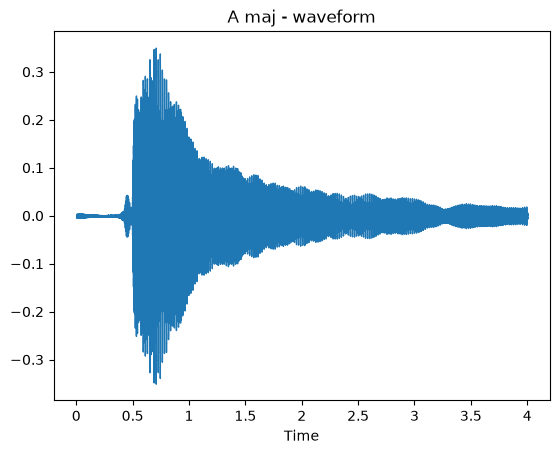

In [4]:
librosa.display.waveshow(aMajor, sr=samplerate)
plt.title('A maj - waveform')
plt.show()

Pass the loaded clip into librosa to produce a ```chromagram```, display the chromagram using ```librosa.display.specshow```, which displays the chromagram w/ automatic axis assignment and labels

In [5]:
chroma = librosa.feature.chroma_cqt(y=aMajor, sr=samplerate)

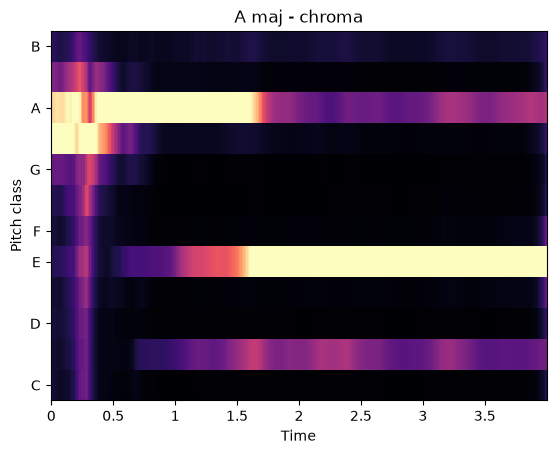

In [6]:
librosa.display.specshow(chroma, y_axis='chroma', x_axis='time', sr=samplerate)
plt.title('A maj - chroma')
plt.show()

A small template dictionary of chords represented as **arrays split into 12 pitch classifications**

In [7]:
# 0=C, 1=C#, 2=D, 3=D#, 4=E, 5=F, 6=F#, 7=G, 8=G#, 9=A, 10=A#, 11=B, exactly like the 12 pitch classes from a chroma
chord_templates = {
    'C':  [1,0,0,0,1,0,0,1,0,0,0,0],
    'G':  [0,0,1,0,0,0,0,1,0,0,0,1],
    'D':  [0,0,1,0,0,0,1,0,0,1,0,0],
    'Em': [0,0,0,0,1,0,0,1,0,0,0,1],
    'Am': [1,0,0,0,1,0,0,0,0,1,0,0],
    'F':  [1,0,0,0,0,1,0,0,0,1,0,0],
    'A':  [0,1,0,0,1,0,0,0,0,1,0,0],
}

Chord Detection function, takes in chroma_frame, which is a frame of the clip and performs ```cosin similarity``` on the audio clips ```chroma frame``` against the ```template chords```. The output is the best matched chord, with the name taken from the template and the certainty of the algorithms assumption. [Geeksforgeeks](https://www.geeksforgeeks.org/dbms/cosine-similarity/#:~:text=The%20formula%20to%20find%20the%20cosine%20similarity%20between%20two%20vectors%20is%20%2D) were my primary reference for the implementation of the algorhtm.

In [8]:
def detect_chord(chroma_frame):
    '''
    :param chroma_frame: section of audio as a chroma, to analyse the notes present and find the best
                        chord match
    :return: the best match chord, taken from the average chroma frame
    '''

    best_match = None
    best_score = -1

    for name, template in chord_templates.items():
        #Cosine similarity: dot product of the the chroma_frame vector and the template of chords vector divided by the product of their magnitudes
        score = np.dot(chroma_frame, template) / (np.linalg.norm(chroma_frame) * np.linalg.norm(template))
        if score > best_score:
            best_match = name
            best_score = score

    return best_match, best_score

In order for the function to detect a chord to work, we can't use the full chroma vector as it contains arrays of chroma vectors, representing frames. The chord detection algorithm expects one single 12 point vector representing the chords chroma. So, using ```numpy``` we can reduce the chroma vector down to an average chroma vector across the clip by using the ```mean``` function 

In [9]:
chroma

array([[0.12969477, 0.11175425, 0.10101627, ..., 0.0832244 , 0.10469038,
        0.13852374],
       [0.11987306, 0.10560787, 0.09498988, ..., 0.3288715 , 0.33248666,
        0.33388087],
       [0.12683067, 0.11508688, 0.10994841, ..., 0.11705577, 0.14644489,
        0.18449867],
       ...,
       [0.8883715 , 0.90206486, 0.9166457 , ..., 0.4655005 , 0.47377685,
        0.49187195],
       [0.39361253, 0.37523338, 0.36754778, ..., 0.12175929, 0.14740062,
        0.1817824 ],
       [0.19875935, 0.17610174, 0.15911332, ..., 0.16422193, 0.17777485,
        0.18836918]], shape=(12, 345), dtype=float32)

```avg_chroma``` averages the chromagram for the audio track into one 12 value vector representing the whole clip. (12 pitch classes)

In [10]:
avg_chroma = np.mean(chroma, axis=1)
avg_chroma

array([0.02710451, 0.29800418, 0.03009104, 0.04695985, 0.7494384 ,
       0.04539629, 0.04289745, 0.05973229, 0.17543456, 0.6264304 ,
       0.08220486, 0.10119869], dtype=float32)

Finally, two variables ```chord and score``` call the ```detect_chord()``` function w/ the ```avg_chroma``` as an argument. The output is the chord name and the result of thecosine similarity representing the algorithms certainty/confidence

In [11]:
chord, score = detect_chord(avg_chroma)
# print w/ score rounded to two decimal places
print(f"The chord is: {chord} , Certainty: {round(score, 2)}")

The chord is: A , Certainty: 0.92


In [12]:
cToG, sr2 = librosa.load('clips/C_to_G.wav', sr=None)

In [13]:
# Compute a separate chromagram for this clip
chroma2 = librosa.feature.chroma_cqt(y=cToG, sr=sr2)

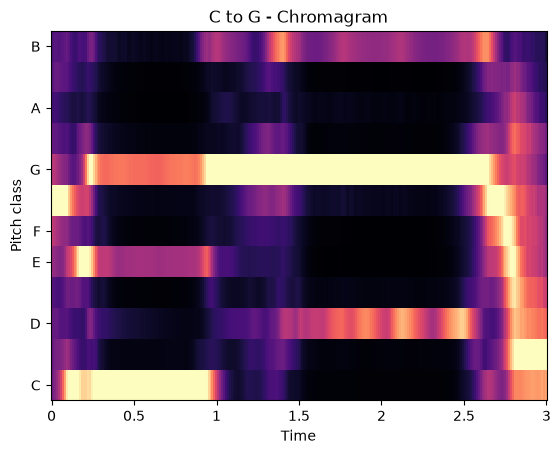

In [14]:
librosa.display.specshow(chroma2, y_axis='chroma', x_axis='time', sr=sr2)
plt.title('C to G - Chromagram')
plt.show()

[This freeCodeCamp article](https://www.freecodecamp.org/news/use-python-to-detect-music-onsets/#:~:text=Finally) details the process of using librosa to detect music **onsets**. An onset is the musical term for the **beginning of a note.** You can use the onset.onset_detect() function and pass in time as an argument for unit of measurement to skip the frame to time conversion

In [15]:
onset_frames = librosa.onset.onset_detect(y=cToG, sr=sr2, units='time')
onset_frames

array([0.03482993, 0.11609977, 0.17414966, 0.23219955, 0.29024943,
       0.98684807, 1.21904762, 1.33514739, 1.36997732, 1.41641723,
       1.46285714, 1.50929705, 1.55573696, 2.53097506, 2.57741497,
       2.79800454])

Redrawing the above chromagram shows the onset times, note the large gaps when not transitioning

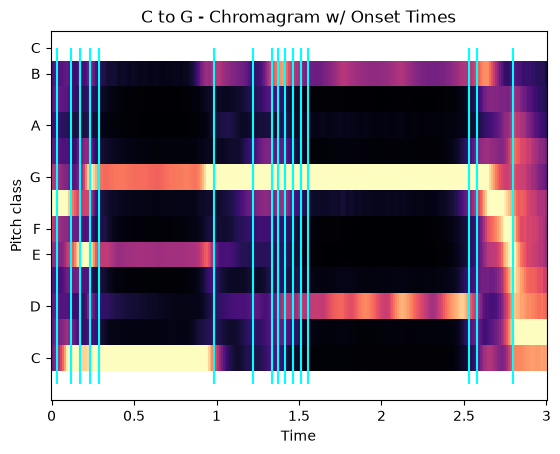

In [16]:
plt.vlines(onset_frames, ymin=-1, ymax=12, color='cyan')
librosa.display.specshow(chroma2, y_axis='chroma', x_axis='time', sr=sr2)
plt.title('C to G - Chromagram w/ Onset Times')
plt.show()

[Geeksforgeeks](https://www.geeksforgeeks.org/python/create-a-voice-recorder-using-python/) have a tutorial detailing recording audio using ```sounddevice```

In [38]:
import sounddevice as sd
from scipy.io.wavfile import write
freq = 44100
# seconds
duration = 5

recording = sd.rec(int(duration * freq), samplerate=freq, channels=2)
sd.wait()

In [39]:
write("clip.wav", freq, recording)

In [23]:
recordedClip, freq = librosa.load('clip.wav', sr=None)

In [19]:
recordingChroma = librosa.feature.chroma_cqt(y=recordedClip, sr=freq)

The external noise from the beginning of the clip shows sanitising the audio with a library like ```noisereduce``` may be necessary. 

This clip was recording using an **Audio Technica AT2020 Condensor Microphone connected to a Scarlett 2i2 audio interface** and, is an **Open C** chord

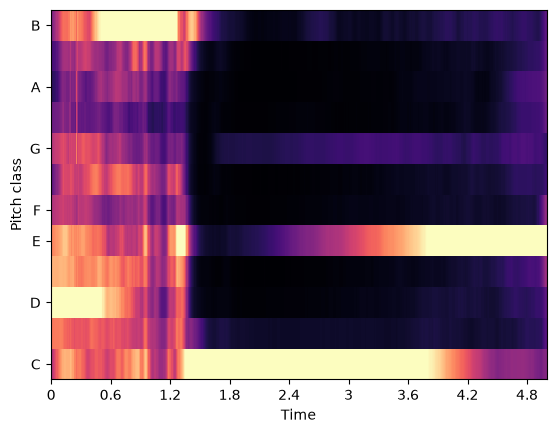

In [20]:
librosa.display.specshow(recordingChroma, y_axis='chroma', x_axis='time', sr=freq)
plt.show()

The chord detection algorithm correctly identifies the chord, despite the noise at the beginning

In [21]:
avg_chroma = np.mean(recordingChroma, axis=1)
chord, score = detect_chord(avg_chroma)
print(f"The chord is: {chord} , Certainty: {round(score, 2)}")

The chord is: C , Certainty: 0.78


For PoC purposes, I have saved the file w/ the chord name concatenated onto the file extension

In [ ]:
write(f"clips/{chord}.wav", freq, recording)

[sounddevice](https://python-sounddevice.readthedocs.io/en/0.4.1/examples.html#recording-with-arbitrary-duration) example programs show how using a callback function on soundddevice's InputStream can create a producer-consumer model for continuous recording.

In [3]:
import queue
import sys
import tempfile
import sounddevice as sd
import soundfile as sf
# producer-consumer model for continuous recording. Using a queue and a callback to 
# produce blocks of audio that are pushed to the queue and then pulled 
# by the q.get(), to consume from the buffer and written to the file
filename = "clips/testclip.wav" 
freq = 44100  
q = queue.Queue()

def callback(indata, _, __, ___):
    """This is called from a separate thread for each audio block."""
    q.put(indata.copy())

try:
    # Make sure the file is opened before starting recording, mode=x ensures that the file can't exist,
    # mode=w however, allowss to overwrite
    with sf.SoundFile(filename, mode="w", samplerate=freq, channels=2,subtype=None) as file:
        # Entering this with block starts the stream, which calls callback for each audio block
        # device=none defaults to systems default
        with sd.InputStream(samplerate=freq, device=None, channels=2, callback=callback):
            print("Recording, press the stop button in Jupyter Notebook to stop")
            while True:
                file.write(q.get())

except KeyboardInterrupt:
    print("\nRecording finished: " + repr(filename))
except Exception as e:
    print(f"Error: {type(e).__name__} - {e}")

ModuleNotFoundError: No module named 'sounddevice'

In [8]:
from ChordDetect import record, analyse
record()
chord, score = analyse()
print(f"The chord is: {chord} , Certainty: {round(score, 2)}")

Recording, press the stop button in Jupyter Notebook to stop

Recording finished: 'clips/testclip.wav'
The chord is: F , Certainty: 0.64
